In [1]:
!pip install hmmlearn

=== TABLA 1: RESULTADOS ESTADÍSTICOS (MÉTRICA: % TIEMPO EN ESTADO CRÍTICO) ===
                        Escenario  Media (%)  Desv. Est. (%)  Mínimo (%)  Máximo (%)  IC Inferior 95%  IC Superior 95%
   Escenario 1: Evolución Natural      13.33             0.0       13.33       13.33            13.33            13.33
Escenario 2: Tratamiento Efectivo       3.33             0.0        3.33        3.33             3.33             3.33
   Escenario 3: Variante Agresiva      46.67             0.0       46.67       46.67            46.67            46.67

Simulación finalizada. Las figuras 'figura1...' y 'figura2...' y el archivo 'resultados_estadisticos.csv' se han guardado exitosamente para el documento del artículo.


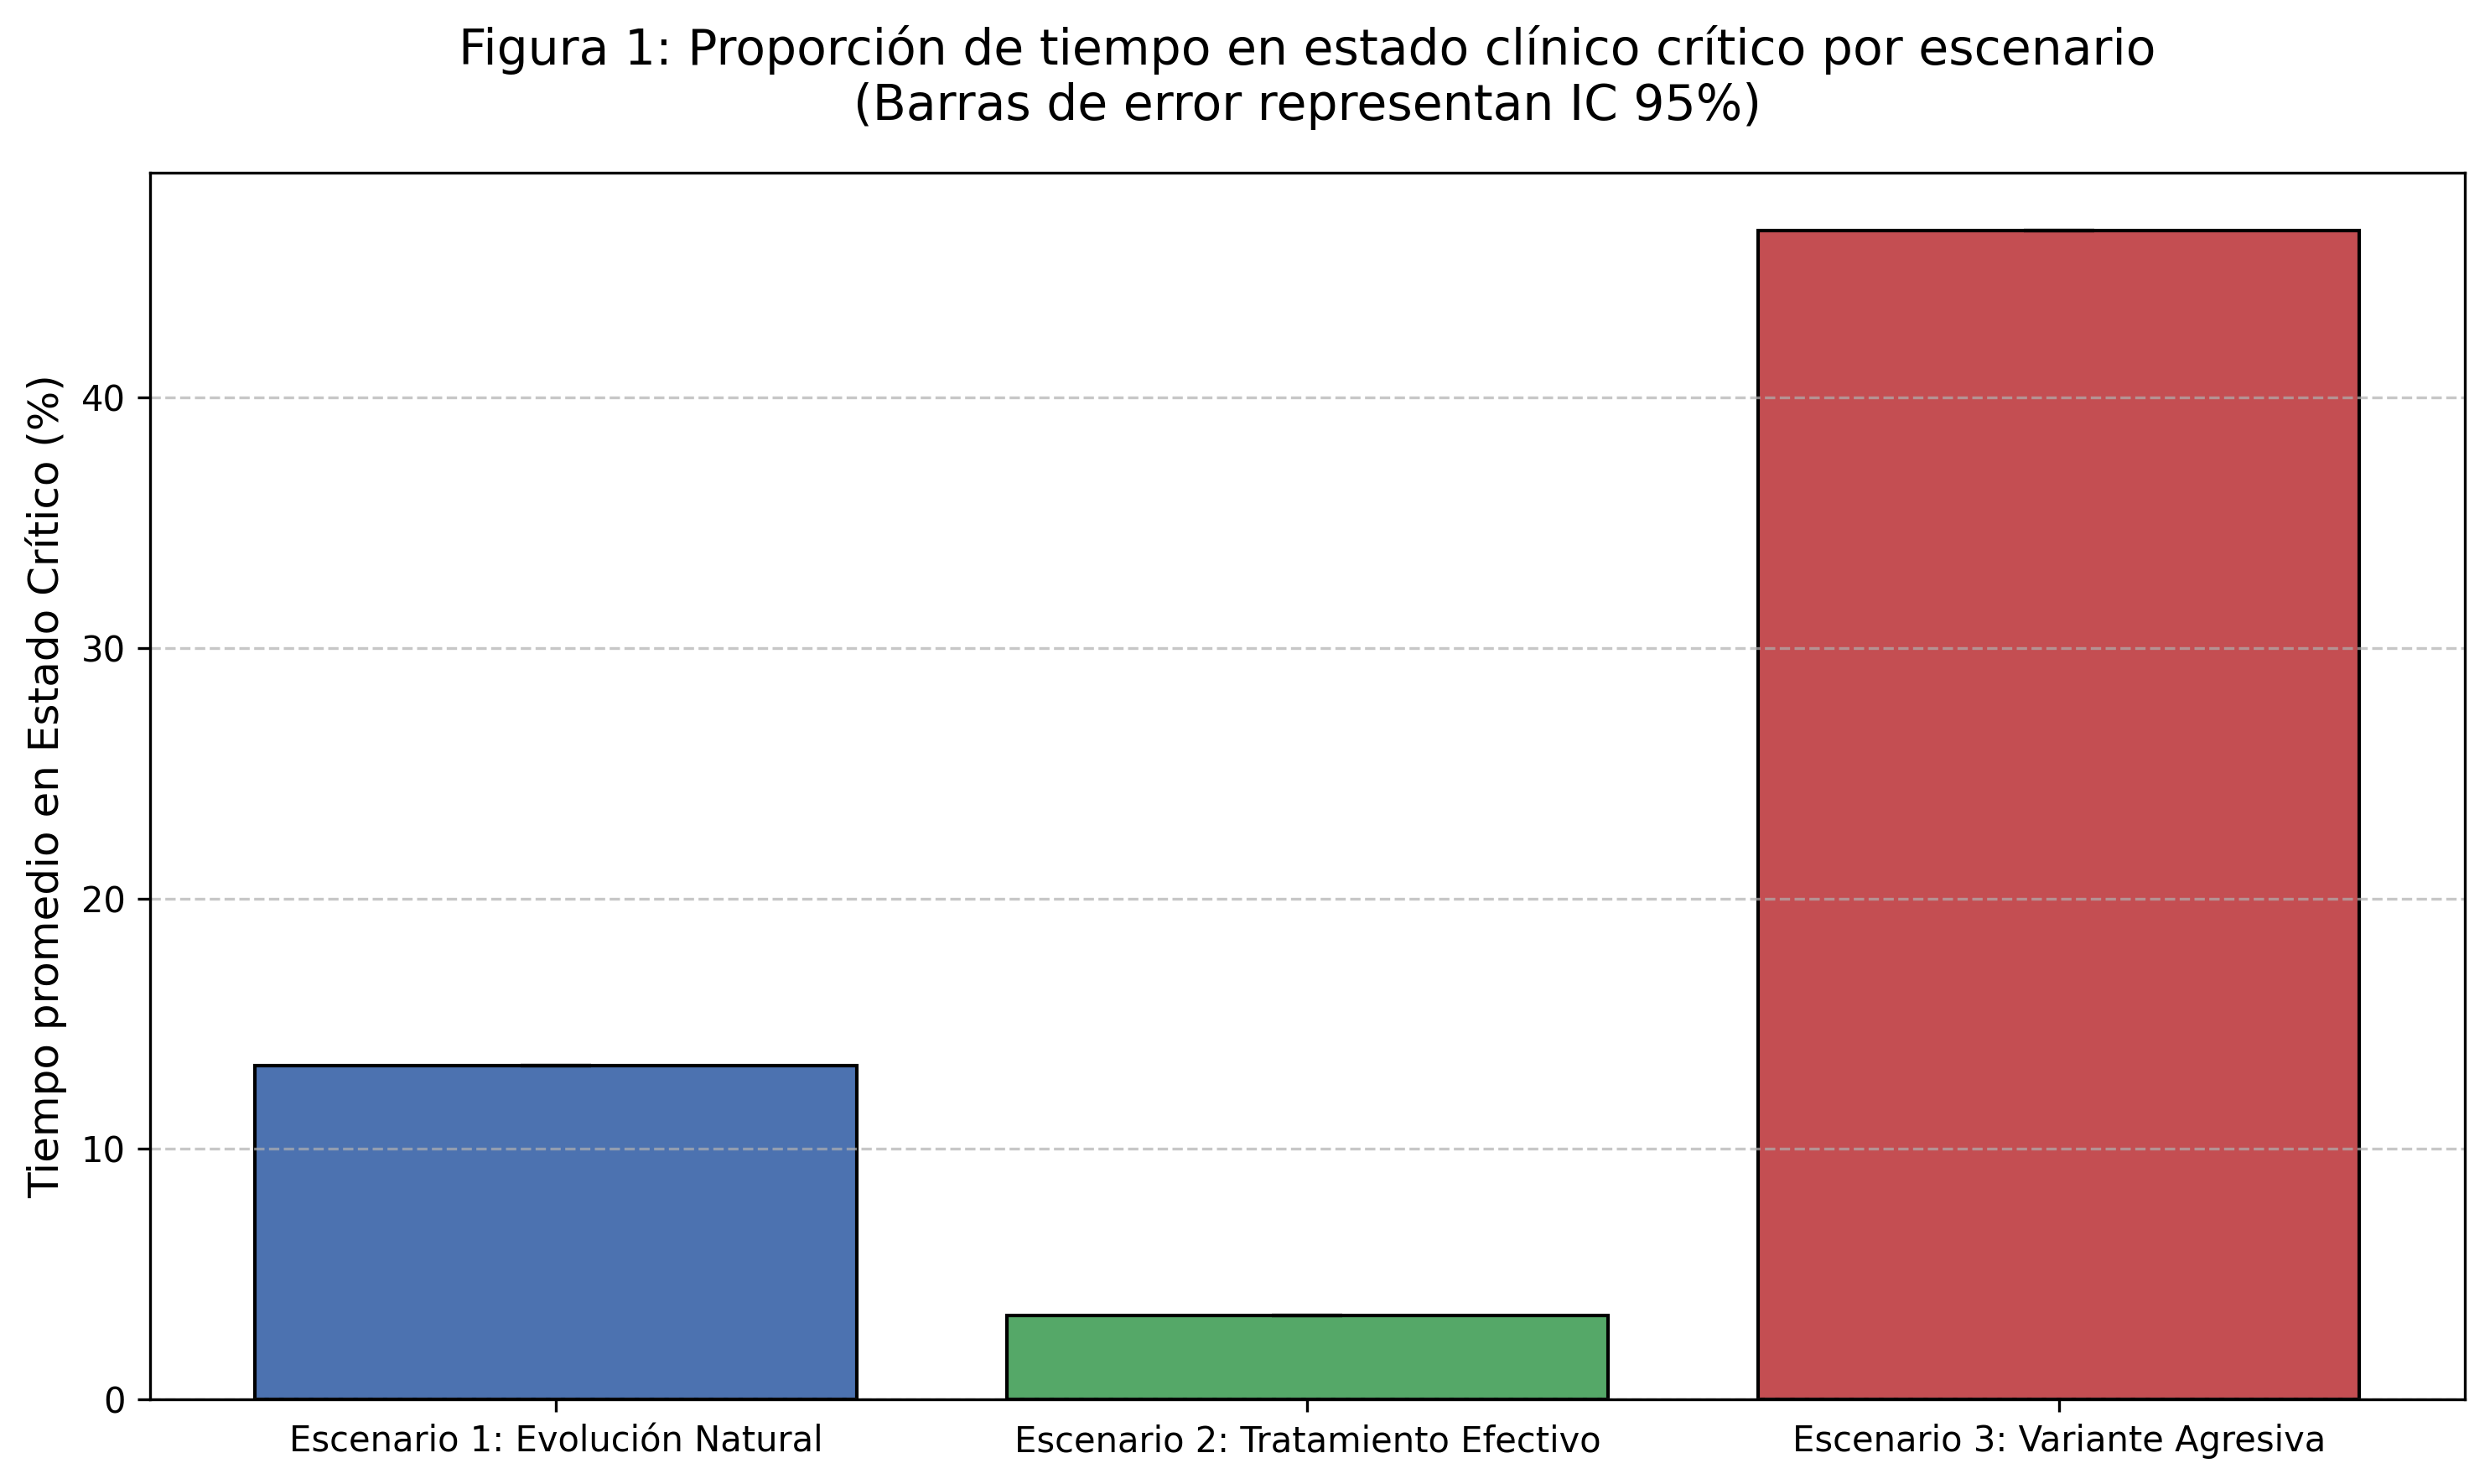

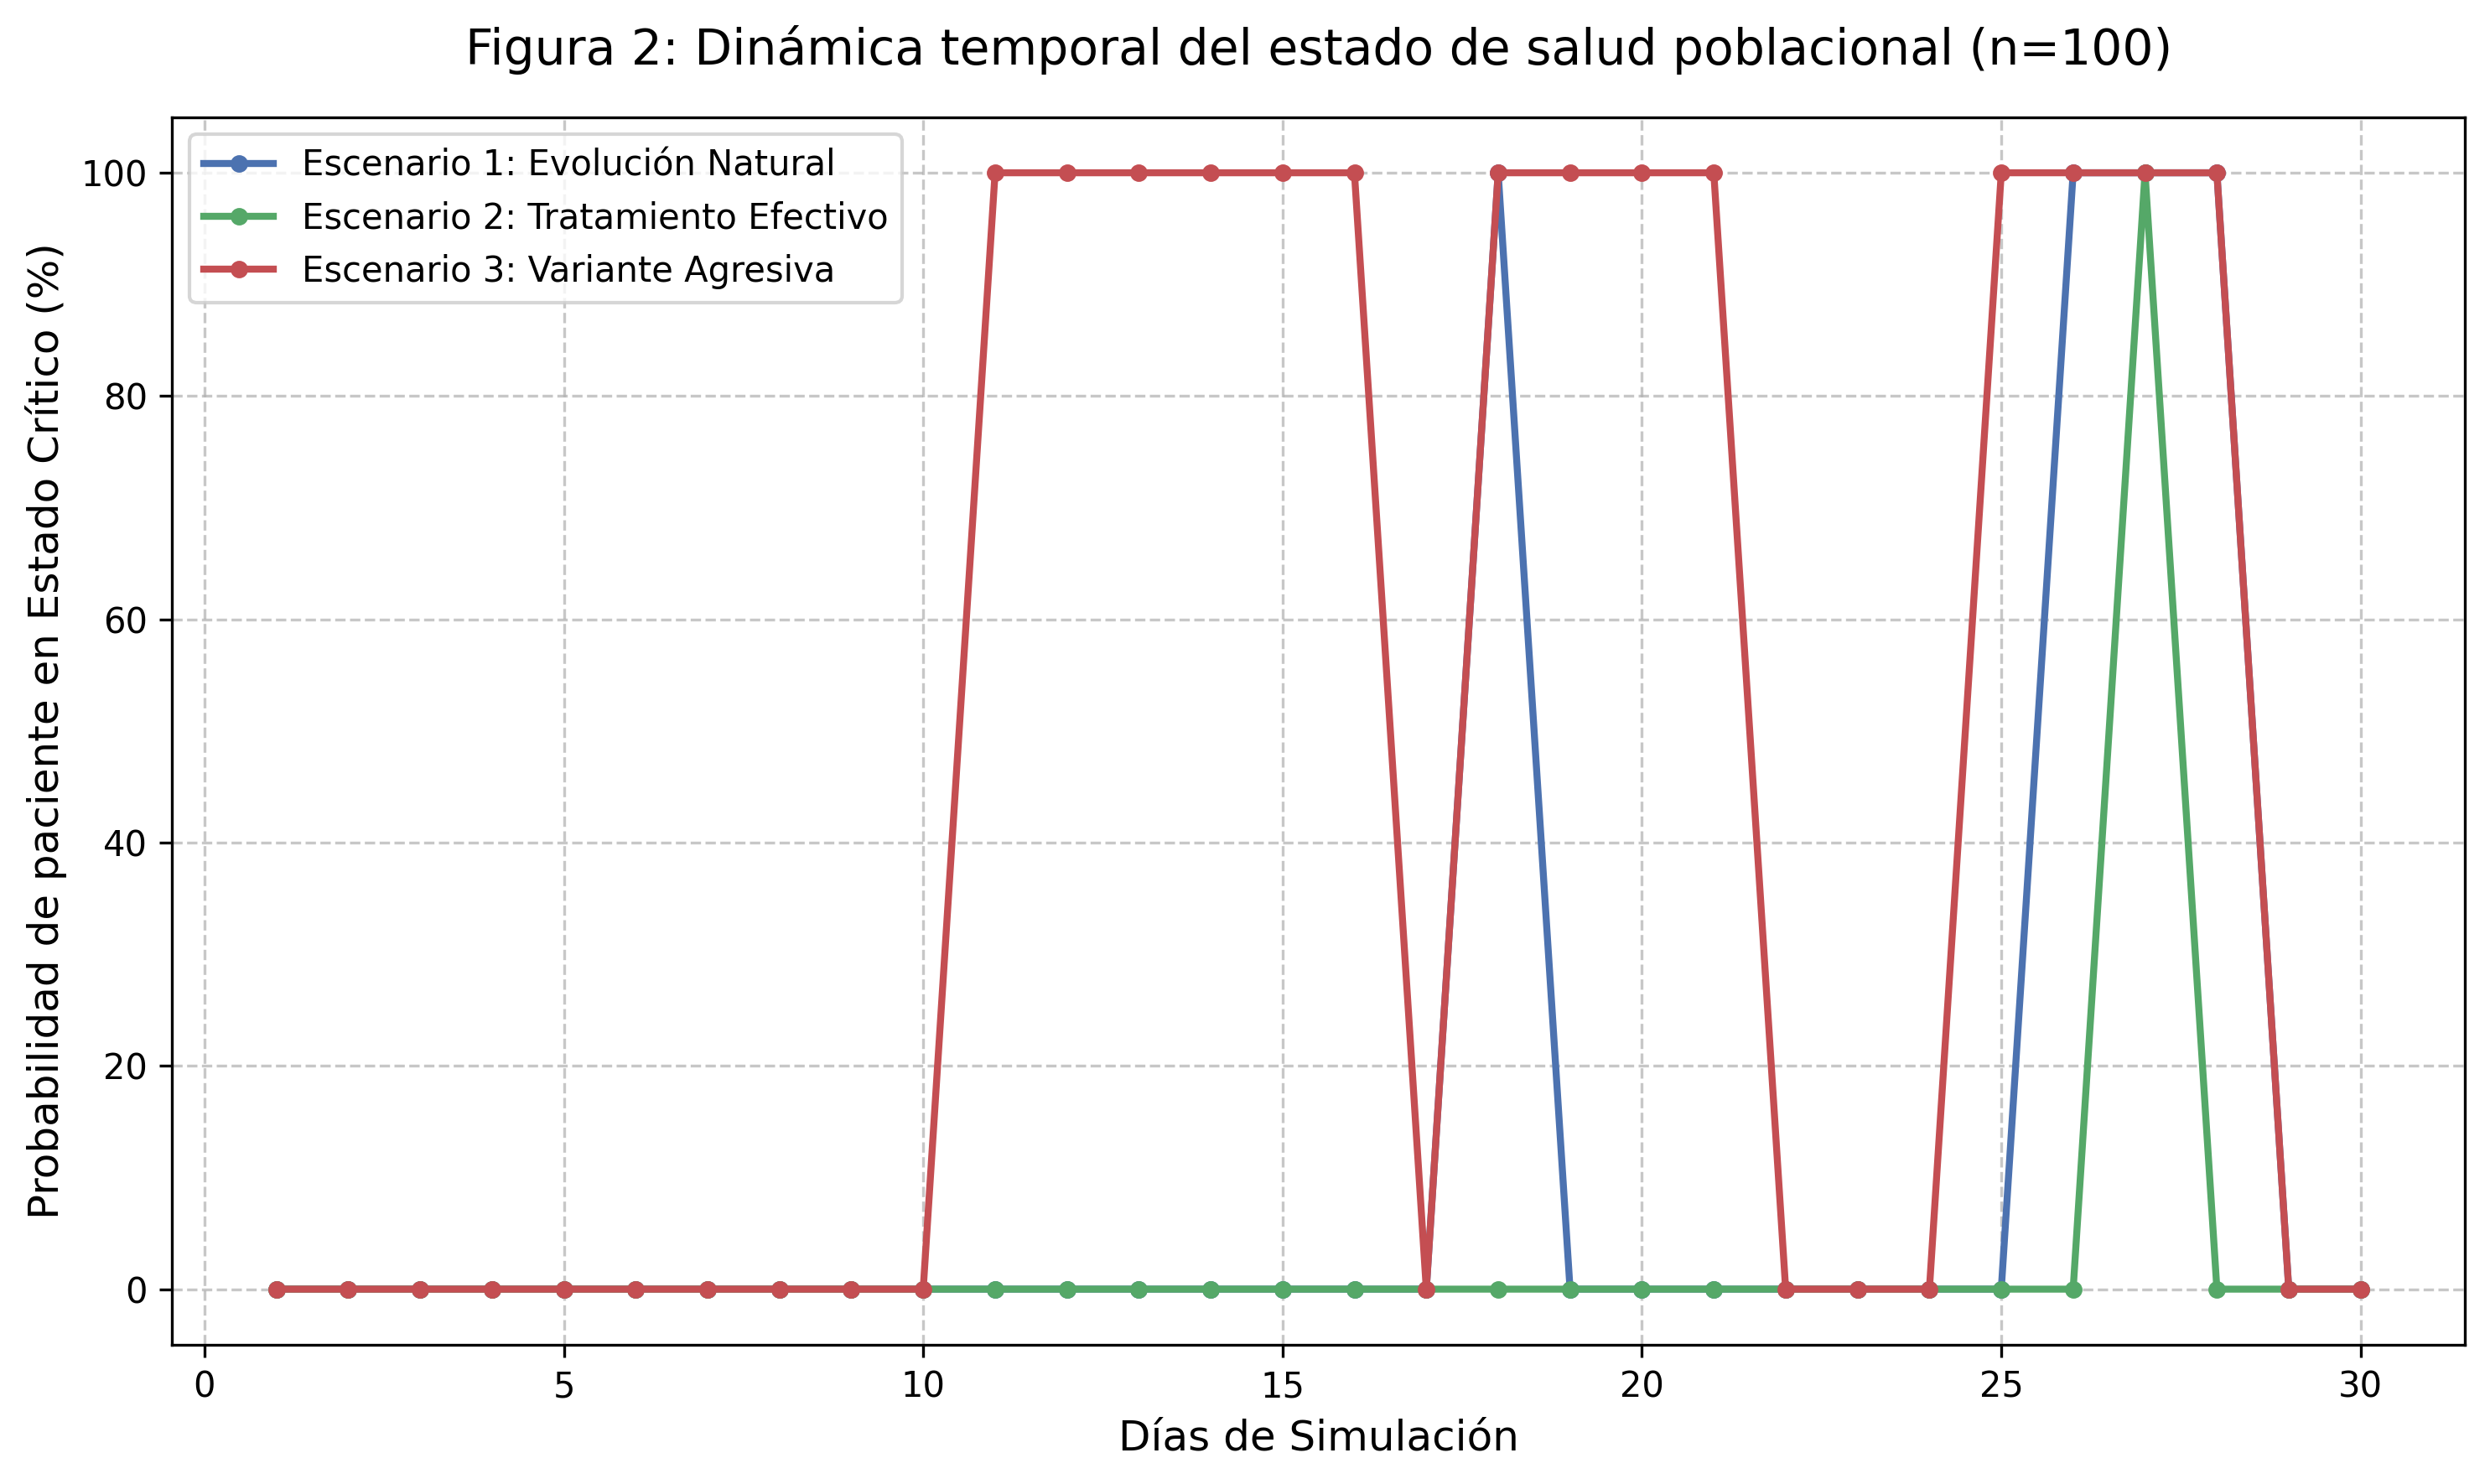

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as st
from hmmlearn import hmm

# ==========================================
# F3: DISEÑO FORMAL DEL MODELO (HMM)
# ==========================================
# Estados Ocultos (S): 0: Saludable, 1: Enfermo Leve, 2: Crítico
# Observaciones (V): 0: Sin síntomas, 1: Fatiga/Malestar, 2: Síntomas Severos

def crear_modelo_hmm(transmat, emissionprob, startprob, seed=42):
    """Crea y retorna un HMM categórico con los parámetros especificados."""
    np.random.seed(seed)
    modelo = hmm.CategoricalHMM(n_components=3, random_state=seed)
    modelo.startprob_ = np.array(startprob)
    modelo.transmat_ = np.array(transmat)
    modelo.emissionprob_ = np.array(emissionprob)
    return modelo

# Distribución Inicial (pi): 80% Saludable, 15% Leve, 5% Crítico
pi_base = [0.80, 0.15, 0.05]

# ==========================================
# F5: DEFINICIÓN DE LOS 3 ESCENARIOS
# ==========================================

# ESCENARIO 1: Evolución Natural (Sin intervención)
A_base = [
    [0.85, 0.10, 0.05], # De Saludable a...
    [0.20, 0.60, 0.20], # De Leve a...
    [0.05, 0.30, 0.65]  # De Crítico a...
]
B_base = [
    [0.80, 0.15, 0.05], # Emisiones siendo Saludable
    [0.20, 0.60, 0.20], # Emisiones siendo Leve
    [0.05, 0.20, 0.75]  # Emisiones siendo Crítico
]

# ESCENARIO 2: Tratamiento Efectivo (Aumenta probabilidad de recuperación)
A_tratamiento = [
    [0.90, 0.08, 0.02],
    [0.40, 0.50, 0.10], # Mayor prob. de Leve -> Saludable
    [0.15, 0.45, 0.40]  # Mayor prob. de Crítico -> Leve/Saludable
]

# ESCENARIO 3: Variante Agresiva (Rápido deterioro)
A_agresivo = [
    [0.70, 0.20, 0.10],
    [0.10, 0.40, 0.50], # Mayor prob. de Leve -> Crítico
    [0.01, 0.10, 0.89]  # Alta retención en estado Crítico
]

escenarios = {
    "Escenario 1: Evolución Natural": (A_base, B_base),
    "Escenario 2: Tratamiento Efectivo": (A_tratamiento, B_base),
    "Escenario 3: Variante Agresiva": (A_agresivo, B_base)
}

# ==========================================
# F5 & F6: SIMULACIÓN Y ANÁLISIS ESTADÍSTICO
# ==========================================
def calcular_intervalo_confianza(data, confidence=0.95):
    """Calcula el intervalo de confianza de la media."""
    a = 1.0 * np.array(data)
    n = len(a)
    m, se = np.mean(a), st.sem(a)
    h = se * st.t.ppf((1 + confidence) / 2., n-1)
    return m - h, m + h

dias_simulacion = 30
n_pacientes = 100 # Iteraciones (muestras) por escenario para robustez estadística
resultados_estadisticos = []
historico_estados_por_escenario = {}

for nombre_escenario, (A, B) in escenarios.items():
    modelo = crear_modelo_hmm(A, B, pi_base)

    tiempo_critico = [] # Métrica: Proporción de días en estado crítico
    historico_estados = np.zeros(dias_simulacion)

    for paciente in range(n_pacientes):
        observaciones, estados_ocultos = modelo.sample(dias_simulacion)
        # Calcular % de tiempo en estado crítico (estado 2)
        prop_critico = np.sum(estados_ocultos == 2) / dias_simulacion
        tiempo_critico.append(prop_critico)
        historico_estados += (estados_ocultos.flatten() == 2).astype(int)

    # Promedio diario de pacientes en estado crítico para gráficas
    historico_estados_por_escenario[nombre_escenario] = historico_estados / n_pacientes

    # Cálculos estadísticos exigidos
    media = np.mean(tiempo_critico)
    desv_est = np.std(tiempo_critico)
    minimo = np.min(tiempo_critico)
    maximo = np.max(tiempo_critico)
    ic_inf, ic_sup = calcular_intervalo_confianza(tiempo_critico)

    resultados_estadisticos.append({
        "Escenario": nombre_escenario,
        "Media (%)": media * 100,
        "Desv. Est. (%)": desv_est * 100,
        "Mínimo (%)": minimo * 100,
        "Máximo (%)": maximo * 100,
        "IC Inferior 95%": ic_inf * 100,
        "IC Superior 95%": ic_sup * 100
    })

# Formatear tabla de resultados
df_resultados = pd.DataFrame(resultados_estadisticos)
df_resultados = df_resultados.round(2)
print("=== TABLA 1: RESULTADOS ESTADÍSTICOS (MÉTRICA: % TIEMPO EN ESTADO CRÍTICO) ===")
print(df_resultados.to_string(index=False))
df_resultados.to_csv("resultados_estadisticos.csv", index=False) # Exportar evidencia

# ==========================================
# F6: GENERACIÓN DE FIGURAS PUBLICABLES
# ==========================================
plt.style.use('default')

# FIGURA 1: Comparación de la métrica principal con barras de error
plt.figure(figsize=(10, 6), dpi=300)
errores = [df_resultados['Media (%)'] - df_resultados['IC Inferior 95%'],
           df_resultados['IC Superior 95%'] - df_resultados['Media (%)']]
plt.bar(df_resultados['Escenario'], df_resultados['Media (%)'], yerr=errores, capsize=10, color=['#4C72B0', '#55A868', '#C44E52'], edgecolor='black')
plt.ylabel('Tiempo promedio en Estado Crítico (%)', fontsize=12)
plt.title('Figura 1: Proporción de tiempo en estado clínico crítico por escenario\n(Barras de error representan IC 95%)', fontsize=14, pad=15)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('figura1_comparacion_escenarios.png', dpi=300)

# FIGURA 2: Evolución diaria de probabilidad de estado crítico (Series de tiempo)
plt.figure(figsize=(10, 6), dpi=300)
colores = ['#4C72B0', '#55A868', '#C44E52']
for (nombre, datos), color in zip(historico_estados_por_escenario.items(), colores):
    plt.plot(range(1, dias_simulacion + 1), datos * 100, label=nombre, marker='o', markersize=4, color=color, linewidth=2)

plt.xlabel('Días de Simulación', fontsize=12)
plt.ylabel('Probabilidad de paciente en Estado Crítico (%)', fontsize=12)
plt.title('Figura 2: Dinámica temporal del estado de salud poblacional (n=100)', fontsize=14, pad=15)
plt.legend(loc='upper left', fontsize=10)
plt.grid(linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('figura2_evolucion_temporal.png', dpi=300)

print("\nSimulación finalizada. Las figuras 'figura1...' y 'figura2...' y el archivo 'resultados_estadisticos.csv' se han guardado exitosamente para el documento del artículo.")